# Task 5 — Attendance Anomaly Detection

Build an unsupervised attendance anomaly detector, add simple rule-based flags, freeze predictions, and only then evaluate against the supplied validation labels using `catch_rate()`.

**Validation-label rule:** The unlocked labels are not used for feature selection, model fitting, rule design, or tuning. They are loaded only in Section 6, after predictions have been generated and saved.

In [1]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DATA_DIR = ROOT / "data"
REPORTS_DIR = ROOT / "reports"
EVIDENCE_DIR = ROOT / "evidence"
REPORTS_DIR.mkdir(exist_ok=True)
EVIDENCE_DIR.mkdir(exist_ok=True)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from cortexhr_helpers import catch_rate

ATTENDANCE_PATH = DATA_DIR / "attendance_monthly_features.csv"
DICTIONARY_PATH = DATA_DIR / "data_dictionary.csv"
BASELINE_BENCHMARKS_PATH = DATA_DIR / "baseline_benchmarks.csv"

for path in [ATTENDANCE_PATH, DICTIONARY_PATH, BASELINE_BENCHMARKS_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required input file not found: {path}")

attendance = pd.read_csv(ATTENDANCE_PATH)
dictionary = pd.read_csv(DICTIONARY_PATH)
baseline_benchmarks = pd.read_csv(BASELINE_BENCHMARKS_PATH)

print("Project root:", ROOT)
print("Attendance data shape:", attendance.shape)
print("Attendance columns:", attendance.columns.tolist())
display(attendance.head())

Project root: /workspace
Attendance data shape: (7339, 16)
Attendance columns: ['attendance_feature_id', 'employee_id', 'month', 'department_id', 'job_level', 'scheduled_days', 'present_days', 'wfh_days', 'half_days_unpaid', 'paid_leave_days', 'unpaid_absence_days', 'longest_unpaid_streak_days', 'late_arrivals', 'avg_hours_worked', 'overtime_hours', 'attendance_rate']


,attendance_feature_id,employee_id,month,department_id,job_level,scheduled_days,present_days,wfh_days,half_days_unpaid,paid_leave_days,unpaid_absence_days,longest_unpaid_streak_days,late_arrivals,avg_hours_worked,overtime_hours,attendance_rate
0,AF-00001,EMP-0002,2025-04-01,D08,4,20,20,18,0,0,0,0,1,8.50,0.0,1.0000
1,AF-00002,EMP-0002,2025-05-01,D08,4,21,20,18,1,0,0,0,2,8.71,0.0,0.9762
2,AF-00003,EMP-0002,2025-06-01,D08,4,21,19,18,1,1,0,0,1,8.25,0.0,0.9286
3,AF-00004,EMP-0002,2025-07-01,D08,4,23,23,22,0,0,0,0,1,8.63,0.0,1.0000
4,AF-00005,EMP-0002,2025-08-01,D08,4,19,19,19,0,0,0,0,1,8.62,0.0,1.0000


## 1. Identify safe attendance features

The attendance baseline supplies the candidate feature list. Identifier columns are kept only for matching predictions to validation labels; they are not model predictors. The anomaly-specific baseline file is read here only to identify its documented feature list, not to access validation labels.

In [2]:
# Locate the supplied anomaly baseline file, including the data/ folder.
anomaly_baseline_candidates = [
    DATA_DIR / "anomaly_baselines.csv",
    ROOT / "anomaly_baselines.csv",
    Path("/mnt/data/anomaly_baselines.csv"),
]
anomaly_baseline_path = next(
    (p for p in anomaly_baseline_candidates if p.exists()),
    None
)
if anomaly_baseline_path is None:
    raise FileNotFoundError(
        "anomaly_baselines.csv not found. Expected it in data/, the project root, or /mnt/data."
    )

anomaly_baselines = pd.read_csv(anomaly_baseline_path)
attendance_baseline_rows = anomaly_baselines[
    anomaly_baselines["task"].astype(str).str.contains(
        "Attendance anomalies", case=False, na=False
    )
]
if attendance_baseline_rows.empty:
    raise ValueError("No attendance-anomaly row found in anomaly_baselines.csv.")

baseline_feature_text = str(attendance_baseline_rows.iloc[0]["features"])
baseline_features = [part.strip() for part in baseline_feature_text.split(",") if part.strip()]

id_candidates = [
    c for c in attendance.columns
    if c.lower() in {
        "attendance_feature_id", "employee_id", "month",
        "observation_date", "row_id"
    } or c.lower().endswith("_id")
]

feature_columns = [
    c for c in baseline_features
    if c in attendance.columns and pd.api.types.is_numeric_dtype(attendance[c])
]

if len(feature_columns) < 2:
    # Conservative fallback: numeric columns excluding identifiers.
    feature_columns = [
        c for c in attendance.select_dtypes(include=np.number).columns
        if c.lower() not in {"row_id", "employee_id"}
        and not c.lower().endswith("_id")
    ]

if not feature_columns:
    raise ValueError("No suitable numeric attendance features were found. Check the data dictionary.")

print("Baseline file:", anomaly_baseline_path)
print("Selected model features:", feature_columns)
print("Identifier/matching columns:", id_candidates)
display(dictionary.head(15))

Baseline file: /workspace/data/anomaly_baselines.csv
Selected model features: ['scheduled_days', 'present_days', 'half_days_unpaid', 'paid_leave_days', 'unpaid_absence_days', 'longest_unpaid_streak_days', 'late_arrivals', 'avg_hours_worked', 'overtime_hours', 'attendance_rate']
Identifier/matching columns: ['attendance_feature_id', 'employee_id', 'month', 'department_id']


,sheet,column,data_type,description,null_count,null_percent,distinct_values,example
0,attrition_dataset,row_id,integer,Row number in the sheet.,0,0.0,2389,1
1,attrition_dataset,employee_id,text,Unique employee code (EMP-0001 ...). Same code...,0,0.0,2383,EMP-0002
2,attrition_dataset,observation_date,date,Date the features were measured (30 Sep 2025 f...,0,0.0,1135,2025-09-30
3,attrition_dataset,department_id,text,Department code (D00 Executive ... D10 Legal &...,0,0.0,10,D08
4,attrition_dataset,role_id,text,Job role code from the roles table.,0,0.0,48,R047
5,attrition_dataset,job_level,integer,"Level 1 to 7 (1 Associate ... 6 Head, 7 CEO).",0,0.0,6,4
6,attrition_dataset,work_location,text,City of the office the employee is attached to.,0,0.0,16,Pune
7,attrition_dataset,work_mode,text,"Onsite, Hybrid or Remote.",0,0.0,3,Remote
8,attrition_dataset,employment_type,text,Permanent or Fixed-Term Contract. Contract sta...,0,0.0,2,Permanent
9,attrition_dataset,highest_education,text,Highest qualification (may be blank).,15,0.6,27,B.E. Computer Science


## 2. Fit the unsupervised Isolation Forest

`contamination=0.03` requests approximately 3% anomalies in the model's predictions. Preprocessing is fitted only on the visible attendance features. No hidden labels are loaded or used.

In [3]:
X = attendance[feature_columns].replace([np.inf, -np.inf], np.nan).copy()

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
X_prepared = preprocessor.fit_transform(X)

isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42,
)
model_prediction = isolation_forest.fit_predict(X_prepared)

# IsolationForest returns -1 for anomaly and 1 for inlier.
attendance["model_anomaly_flag"] = (model_prediction == -1).astype(int)
attendance["anomaly_score"] = -isolation_forest.score_samples(X_prepared)

print("Rows scored:", len(attendance))
print("Model-flagged anomalies:", int(attendance["model_anomaly_flag"].sum()))
print("Model flagged percentage:", f'{attendance["model_anomaly_flag"].mean():.2%}')

Rows scored: 7339
Model-flagged anomalies: 221
Model flagged percentage: 3.01%


## 3. Add simple attendance rules

These interpretable rules use only the visible attendance measurements. Thresholds are set without consulting the unlocked validation labels.

In [4]:
rule_flags = pd.DataFrame(index=attendance.index)
rule_descriptions = []

if "attendance_rate" in attendance.columns:
    rule_flags["rule_low_attendance"] = (
        pd.to_numeric(attendance["attendance_rate"], errors="coerce") < 0.75
    ).fillna(False).astype(int)
    rule_descriptions.append("attendance_rate < 0.75")

if "longest_unpaid_streak_days" in attendance.columns:
    rule_flags["rule_long_unpaid_streak"] = (
        pd.to_numeric(attendance["longest_unpaid_streak_days"], errors="coerce") >= 5
    ).fillna(False).astype(int)
    rule_descriptions.append("longest_unpaid_streak_days >= 5")

if "unpaid_absence_days" in attendance.columns:
    rule_flags["rule_unpaid_absence"] = (
        pd.to_numeric(attendance["unpaid_absence_days"], errors="coerce") >= 5
    ).fillna(False).astype(int)
    rule_descriptions.append("unpaid_absence_days >= 5")

if "late_arrivals" in attendance.columns:
    rule_flags["rule_frequent_lateness"] = (
        pd.to_numeric(attendance["late_arrivals"], errors="coerce") >= 5
    ).fillna(False).astype(int)
    rule_descriptions.append("late_arrivals >= 5")

if rule_flags.shape[1] == 0:
    raise ValueError("No supported attendance-rule columns were found; inspect the column names.")

attendance["rule_anomaly_flag"] = rule_flags.max(axis=1).astype(int)
attendance["combined_anomaly_flag"] = (
    (attendance["model_anomaly_flag"] == 1) |
    (attendance["rule_anomaly_flag"] == 1)
).astype(int)

print("Rules applied:")
for rule in rule_descriptions:
    print("-", rule)
print("Rule-flagged rows:", int(attendance["rule_anomaly_flag"].sum()))
print("Combined flagged rows:", int(attendance["combined_anomaly_flag"].sum()))

Rules applied:
- attendance_rate < 0.75
- longest_unpaid_streak_days >= 5
- unpaid_absence_days >= 5
- late_arrivals >= 5
Rule-flagged rows: 611
Combined flagged rows: 646


## 4. Freeze and save predictions before validation

This prediction file is written before the notebook loads the unlocked labels. Do not change features, model settings, or rules after looking at the evaluation results and then describe the same evaluation as untouched.

In [5]:
key_columns = [
    c for c in ["attendance_feature_id", "employee_id", "month"]
    if c in attendance.columns
]
if "attendance_feature_id" not in key_columns:
    raise ValueError(
        "attendance_feature_id is required to match predictions with unlock_CX-05 labels."
    )

prediction_columns = key_columns + feature_columns + [
    "anomaly_score", "model_anomaly_flag",
    "rule_anomaly_flag", "combined_anomaly_flag"
]
predictions = attendance[prediction_columns].copy()
predictions["attendance_feature_id"] = predictions["attendance_feature_id"].astype(str)

predictions_path = REPORTS_DIR / "task5_attendance_anomaly_predictions.csv"
predictions.to_csv(predictions_path, index=False)

rule_summary = pd.DataFrame({
    "detector": ["Isolation Forest", "Rule-based", "Combined"],
    "flagged_rows": [
        int(attendance["model_anomaly_flag"].sum()),
        int(attendance["rule_anomaly_flag"].sum()),
        int(attendance["combined_anomaly_flag"].sum()),
    ],
})
rule_summary["flagged_percent"] = rule_summary["flagged_rows"] / len(attendance) * 100
display(rule_summary)
rule_summary.to_csv(REPORTS_DIR / "task5_detector_flag_counts.csv", index=False)

print("Predictions frozen at:", predictions_path)
print("No unlock/validation labels have been loaded so far.")

,detector,flagged_rows,flagged_percent
0,Isolation Forest,221,3.011309
1,Rule-based,611,8.325385
2,Combined,646,8.802289


Predictions frozen at: /workspace/reports/task5_attendance_anomaly_predictions.csv
No unlock/validation labels have been loaded so far.


## 5. Inspect detector flags

These summaries and the plot describe the detector's predictions only; they do not use hidden labels.

,detector,flagged_rows,flagged_percent
0,Isolation Forest,221,3.011309
1,Rule-based,611,8.325385
2,Combined,646,8.802289


,attendance_feature_id,employee_id,month,scheduled_days,present_days,half_days_unpaid,paid_leave_days,unpaid_absence_days,longest_unpaid_streak_days,late_arrivals,avg_hours_worked,overtime_hours,attendance_rate,anomaly_score,model_anomaly_flag,rule_anomaly_flag,combined_anomaly_flag
3169,AF-03170,EMP-0356,2025-07-01,23,0,0,2,21,21,0,0.00,0.0,0.0000,0.785901,1,1,1
5917,AF-05918,EMP-0585,2025-09-01,22,0,0,0,22,22,0,0.00,0.0,0.0000,0.785499,1,1,1
6801,AF-06802,EMP-0646,2026-06-01,22,0,0,0,22,22,0,0.00,0.0,0.0000,0.785499,1,1,1
2818,AF-02819,EMP-0318,2026-06-01,22,0,0,0,22,22,0,0.00,0.0,0.0000,0.785499,1,1,1
493,AF-00494,EMP-0056,2025-11-01,20,0,0,0,20,20,0,0.00,0.0,0.0000,0.784587,1,1,1
5660,AF-05661,EMP-0570,2025-11-01,20,0,0,0,20,20,0,0.00,0.0,0.0000,0.784587,1,1,1
4332,AF-04333,EMP-0460,2025-10-01,20,0,0,0,20,20,0,0.00,0.0,0.0000,0.784587,1,1,1
735,AF-00736,EMP-0087,2026-05-01,20,0,0,0,20,20,0,0.00,0.0,0.0000,0.784587,1,1,1
6634,AF-06635,EMP-0633,2026-08-01,21,0,0,0,21,21,0,0.00,0.0,0.0000,0.784236,1,1,1
3111,AF-03112,EMP-0347,2026-09-01,21,0,0,0,21,21,0,0.00,0.0,0.0000,0.784236,1,1,1


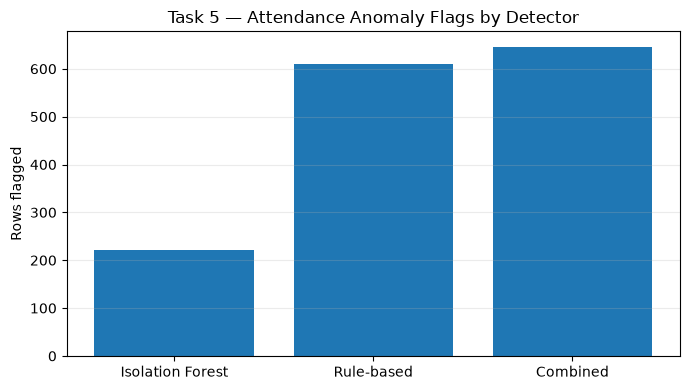

In [6]:
display(rule_summary)
display(
    attendance.loc[
        attendance["combined_anomaly_flag"] == 1,
        key_columns + feature_columns + [
            "anomaly_score", "model_anomaly_flag",
            "rule_anomaly_flag", "combined_anomaly_flag"
        ]
    ].sort_values("anomaly_score", ascending=False).head(20)
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rule_summary["detector"], rule_summary["flagged_rows"])
ax.set_ylabel("Rows flagged")
ax.set_title("Task 5 — Attendance Anomaly Flags by Detector")
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "task5_detector_flag_counts.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 6. Final evaluation against `unlock_CX-05`

**Run this section only after the prediction file is saved.** The unlock file is loaded solely to evaluate the frozen predictions. It must not be used to fit, design, or tune the detector.

Loaded labels for evaluation only: /workspace/04_Validation_Vault/unlock_CX-05_attendance_anomaly_labels.csv


,attendance_feature_id,employee_id,month,anomaly_type,injection_note
0,AF-04604,EMP-0484,2025-12-01,ABSENCE_STREAK,10 consecutive unpaid absence days
1,AF-02143,EMP-0249,2026-07-01,ABSENCE_STREAK,13 consecutive unpaid absence days
2,AF-01814,EMP-0208,2026-01-01,ABSENCE_STREAK,9 consecutive unpaid absence days
3,AF-00927,EMP-0100,2025-10-01,ABSENCE_STREAK,14 consecutive unpaid absence days
4,AF-03762,EMP-0414,2025-12-01,ABSENCE_STREAK,12 consecutive unpaid absence days


,detector,flagged,real,caught,precision,recall
0,Isolation Forest,221,150,89,0.402715,0.593333
1,Rule-based,611,150,117,0.191489,0.780000
2,Combined,646,150,119,0.184211,0.793333


,anomaly_type,missed_count
0,IMPOSSIBLE_HOURS,31


Saved missed-anomaly analysis note: /workspace/reports/task5_missed_anomaly_analysis.md


,detector,flagged,injected,precision,recall
0,Supplied Isolation Forest baseline,221,150,0.403000,0.593000
1,Our Isolation Forest,221,150,0.402715,0.593333
2,Our combined detector,646,150,0.184211,0.793333


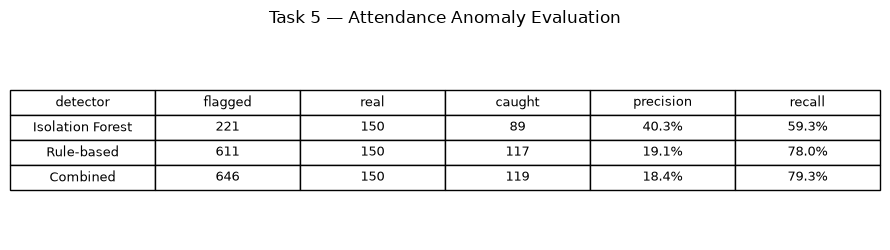

Evaluation complete. Validation labels were used only after predictions were frozen.


In [7]:
unlock_candidates = [
    ROOT / "04_Validation_Vault" / "unlock_CX-05_attendance_anomaly_labels.csv",
    DATA_DIR / "04_Validation_Vault" / "unlock_CX-05_attendance_anomaly_labels.csv",
    ROOT / "04_Validation_Vault" / "unlock_CX-05.csv",
    DATA_DIR / "04_Validation_Vault" / "unlock_CX-05.csv",
    Path("/mnt/data/unlock_CX-05_attendance_anomaly_labels.csv"),
]
unlock_path = next((p for p in unlock_candidates if p.exists()), None)

if unlock_path is None:
    raise FileNotFoundError(
        "Could not locate unlock_CX-05. Place the file in 04_Validation_Vault "
        "or data/04_Validation_Vault, or update unlock_candidates."
    )

# First read of hidden labels: evaluation only.
unlock = pd.read_csv(unlock_path)
print("Loaded labels for evaluation only:", unlock_path)
display(unlock.head())

required_label_columns = {"attendance_feature_id", "anomaly_type"}
if not required_label_columns.issubset(unlock.columns):
    raise ValueError(f"Unlock file must contain columns: {sorted(required_label_columns)}")
if unlock["attendance_feature_id"].duplicated().any():
    raise ValueError("Unlock labels contain duplicate attendance_feature_id values.")

truth_ids = set(unlock["attendance_feature_id"].astype(str))
prediction_eval = predictions.copy()
prediction_eval["attendance_feature_id"] = prediction_eval["attendance_feature_id"].astype(str)

def flagged_ids(flag_column):
    return set(
        prediction_eval.loc[prediction_eval[flag_column] == 1, "attendance_feature_id"]
    )

model_catch = catch_rate(flagged_ids("model_anomaly_flag"), truth_ids)
rule_catch = catch_rate(flagged_ids("rule_anomaly_flag"), truth_ids)
combined_catch = catch_rate(flagged_ids("combined_anomaly_flag"), truth_ids)

evaluation_table = pd.DataFrame([
    {"detector": "Isolation Forest", **model_catch},
    {"detector": "Rule-based", **rule_catch},
    {"detector": "Combined", **combined_catch},
])
display(evaluation_table)
evaluation_table.to_csv(REPORTS_DIR / "task5_catch_rate_results.csv", index=False)

# Missed injected anomalies for the combined detector.
combined_flagged_ids = flagged_ids("combined_anomaly_flag")
missed = unlock.loc[
    ~unlock["attendance_feature_id"].astype(str).isin(combined_flagged_ids)
].copy()
missed_types = (
    missed["anomaly_type"].value_counts()
    .rename_axis("anomaly_type")
    .reset_index(name="missed_count")
)
display(missed_types)
missed.to_csv(REPORTS_DIR / "task5_missed_anomalies.csv", index=False)
missed_types.to_csv(REPORTS_DIR / "task5_missed_anomaly_types.csv", index=False)

# Save a readable missed-anomaly note grounded in the observed counts.
total_injected = len(unlock)
total_missed = len(missed)
lines = [
    "# Task 5 — Missed Anomaly Analysis",
    "",
    f"The combined detector caught {combined_catch['caught']} of {total_injected} injected anomalies "
    f"(recall {combined_catch['recall']:.2%}) and flagged {combined_catch['flagged']} records "
    f"(precision {combined_catch['precision']:.2%}).",
    "",
    f"It missed {total_missed} injected anomalies. The observed missed types are:",
    "",
]
if missed_types.empty:
    lines.append("- No missed anomaly types were observed in this evaluation.")
else:
    for _, row in missed_types.iterrows():
        lines.append(f"- **{row['anomaly_type']}**: {int(row['missed_count'])} missed.")
lines += [
    "",
    "## Interpretation",
    "",
    "The rules explicitly check low attendance, long unpaid-absence streaks, high unpaid-absence counts, "
    "and frequent lateness. Anomaly types that do not strongly affect these measurements may be missed. "
    "Isolation Forest detects unusual feature combinations, but it does not guarantee detection of every "
    "injected anomaly.",
    "",
    "These are plausible explanations based on the detector design, not verified causes for each missed row. "
    "Use the missed-anomalies CSV and the data dictionary to inspect the relevant features. The unlocked labels "
    "were used only for evaluation, not for model fitting or threshold tuning.",
    "",
    "This detector should support data-quality checks and human review, not automated employment decisions.",
]
missed_note_path = REPORTS_DIR / "task5_missed_anomaly_analysis.md"
missed_note_path.write_text("\n".join(lines) + "\n", encoding="utf-8")
print("Saved missed-anomaly analysis note:", missed_note_path)

# Compare the supplied Isolation Forest baseline with our measured Isolation Forest
# and combined detector. The baseline metrics are read from anomaly_baselines.csv.
attendance_baseline = anomaly_baselines[
    anomaly_baselines["task"].astype(str).str.contains(
        "Attendance anomalies", case=False, na=False
    )
]
if attendance_baseline.empty:
    raise ValueError("No attendance-anomaly baseline row found.")

b = attendance_baseline.iloc[0]
comparison = pd.DataFrame([
    {
        "detector": "Supplied Isolation Forest baseline",
        "flagged": int(b["flagged"]),
        "injected": int(b["injected"]),
        "precision": float(b["precision"]),
        "recall": float(b["recall"]),
    },
    {
        "detector": "Our Isolation Forest",
        "flagged": int(model_catch["flagged"]),
        "injected": int(model_catch["real"]),
        "precision": float(model_catch["precision"]),
        "recall": float(model_catch["recall"]),
    },
    {
        "detector": "Our combined detector",
        "flagged": int(combined_catch["flagged"]),
        "injected": int(combined_catch["real"]),
        "precision": float(combined_catch["precision"]),
        "recall": float(combined_catch["recall"]),
    },
])
display(comparison)
comparison.to_csv(REPORTS_DIR / "task5_baseline_comparison.csv", index=False)

# Render a readable metrics-table evidence image.
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.axis("off")
metrics_for_plot = evaluation_table[["detector", "flagged", "real", "caught", "precision", "recall"]].copy()
for col in ["precision", "recall"]:
    metrics_for_plot[col] = metrics_for_plot[col].map(lambda x: f"{x:.1%}")
table = ax.table(
    cellText=metrics_for_plot.values,
    colLabels=metrics_for_plot.columns,
    loc="center",
    cellLoc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 1.5)
ax.set_title("Task 5 — Attendance Anomaly Evaluation", pad=12)
fig.tight_layout()
fig.savefig(EVIDENCE_DIR / "task5_evaluation_metrics.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Evaluation complete. Validation labels were used only after predictions were frozen.")

## 7. Final output checklist

Every expected output is checked, including the baseline comparison, missed-anomaly note, and evaluation metrics evidence. Review the actual tables and note before updating README, SUBMISSION, or the Phase 1 report.

In [8]:
expected_outputs = [
    REPORTS_DIR / "task5_attendance_anomaly_predictions.csv",
    REPORTS_DIR / "task5_detector_flag_counts.csv",
    EVIDENCE_DIR / "task5_detector_flag_counts.png",
    REPORTS_DIR / "task5_catch_rate_results.csv",
    REPORTS_DIR / "task5_missed_anomalies.csv",
    REPORTS_DIR / "task5_missed_anomaly_types.csv",
    REPORTS_DIR / "task5_missed_anomaly_analysis.md",
    REPORTS_DIR / "task5_baseline_comparison.csv",
    EVIDENCE_DIR / "task5_evaluation_metrics.png",
]
output_check = pd.DataFrame({
    "file": [str(p.relative_to(ROOT)) for p in expected_outputs],
    "exists": [p.exists() for p in expected_outputs],
})
display(output_check)
if not output_check["exists"].all():
    print("Some outputs are missing. Review the earlier cell errors before submitting.")
else:
    print("All expected Task 5 outputs exist.")

,file,exists
0,reports/task5_attendance_anomaly_predictions.csv,True
1,reports/task5_detector_flag_counts.csv,True
2,evidence/task5_detector_flag_counts.png,True
3,reports/task5_catch_rate_results.csv,True
4,reports/task5_missed_anomalies.csv,True
5,reports/task5_missed_anomaly_types.csv,True
6,reports/task5_missed_anomaly_analysis.md,True
7,reports/task5_baseline_comparison.csv,True
8,evidence/task5_evaluation_metrics.png,True


All expected Task 5 outputs exist.
